### Test extra plotting functionalities

In [ ]:
import emg3d
import numpy as np
from Emg3d_extra_grid_functions_v26 import *

#### Construct test model

In [114]:
# Source
source = [0, -126, 0, 90.0, 0] # y-directed point dipole on the surface

# Source frequency
frequency = 1

# Receiver offsets
offsets = np.arange(0, 300, 7.5)  # 300 m long receiver line

# receiver-array: x, y, z, azimuth, dip
receivers = (offsets*0, [74]*len(offsets), -offsets, 0, 90)  # z-directed, Ez response

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -150, -200]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 50, 10, 50]) # base incl. air (lower res, because of 3D modelling)


In [115]:
#Use grid with large grid cells so mistakes become clear

grid = emg3d.construct_mesh(
    center=(0,0,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-300, 300], [-300, 300], [-250, 0]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [50, 50, 25],
)
 
grid  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 110,592 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     48   -103,295.57    103,295.57     50.00 30,985.07    1.43
   y     48   -103,295.57    103,295.57     50.00 30,985.07    1.43
   z     48   -105,197.15    156,953.06     25.00 51,980.91    1.49

In [116]:
#Insert resistivity values into the grid

# Pre-allocate an array with number of cells corresponding to our grid
res_base = np.ones(grid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    res_base[:, :, (grid.cell_centers_z > dd[i+1]) & (grid.cell_centers_z <= dd[i])] = resistivities_base[i]

model_base = emg3d.Model(grid, property_x=res_base, mapping='Resistivity')

#### Test index-finding functions

A question arises of which cell to pick when a point is exactly at the edge between cells. The way it's implemented, the point2index function always rounds up so that in this case the cell furthest away from the center is selected. This ensures that when picking indeces of coordinates with the opposite sign, the same cells will be selected symmetric to the origin.

Note: when testing make sure the points requested are inside the homogeneous spacing region (domain)

In [117]:
point2index_xyz(grid, (150, 150, -162), QC=True, Extra_QC=True)

x-spacing: 50.0
y-spacing: 50.0
z-spacing: 25.0
grid center:  [ 25.   25.  -87.5]
x-steps: 3
y-steps: 3
z-steps: -3
ix: 27
iy: 27
iz: 21
x:  174.99999999999858
y:  174.99999999999858
z:  -162.49999999997695


(27, 27, 21)

In [118]:
point2index_xyz(grid, (-150, -150, -162), QC=True, Extra_QC=True)

x-spacing: 50.0
y-spacing: 50.0
z-spacing: 25.0
grid center:  [ 25.   25.  -87.5]
x-steps: -4
y-steps: -4
z-steps: -3
ix: 20
iy: 20
iz: 21
x:  -175.00000000000142
y:  -175.00000000000142
z:  -162.49999999997695


(20, 20, 21)

In [119]:
point2index_xyz(grid, (-149, -149, -162), QC=True, Extra_QC=True)


x-spacing: 50.0
y-spacing: 50.0
z-spacing: 25.0
grid center:  [ 25.   25.  -87.5]
x-steps: -3
y-steps: -3
z-steps: -3
ix: 21
iy: 21
iz: 21
x:  -125.00000000000142
y:  -125.00000000000142
z:  -162.49999999997695


(21, 21, 21)

#### Adapt model using extra functionalities

In [120]:
#Use predefined function to insert a cuboid inton the target layer

x_extent = 150
y_extent = 150
zmin = -200#depth[2] # -200
zmax = -160#depth[1] # -150
res_QC = 13.1 #now: aquifer +50 °Celsius

res_QC = change_grid_values(res_base.copy(), grid, x_extent, y_extent, zmin, zmax, res_QC)

model_QC = emg3d.Model(grid, property_x=res_QC, mapping='Resistivity')

[-149, -149, -199] [149, 149, -161]
x:  -125.00000000000142
y:  -125.00000000000142
z:  -187.49999999997695
x:  124.99999999999858
y:  124.99999999999858
z:  -162.49999999997695
x bounds:  -125.00000000000142  ,  124.99999999999858
y_bounds:  -125.00000000000142  ,  124.99999999999858
z_bounds:  -187.49999999997695  ,  -162.49999999997695


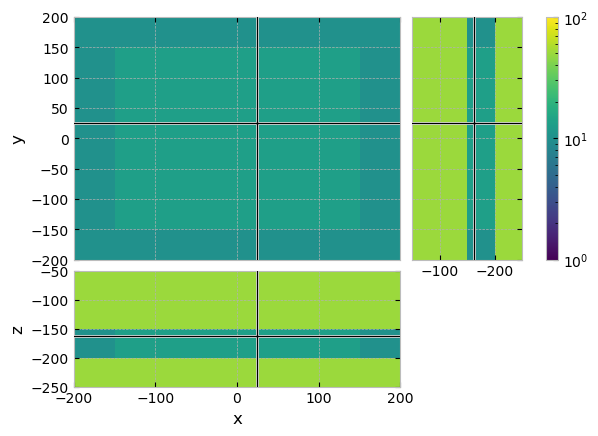

In [121]:
#QC cube location
grid.plot_3d_slicer(
    model_QC.property_x,
    pcolor_opts={'norm': LogNorm(vmin=1, vmax=100)},
    xlim=[-200, 200],
    ylim=[-200, 200],
    zlim=[-250, -50],
    zslice=-160,
)
fig = plt.gcf()